# 04 · Avaliação final: modelos clássicos (SVM, LOF, Isolation Forest)

Este notebook só lê resultados salvos; não treina nem reavalia nada.

1. Etapa 8: modelos com vetor global (HOG/Gabor/bordas/geometria) no teste completo.
2. Etapa 9: diagnóstico e modelos com descritores locais na ROI alinhada, escolhidos na metade de seleção e avaliados uma vez no holdout.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / 'src').exists():
    ROOT = ROOT.parent
R = ROOT / 'results'

## Etapa 8: vetor global no teste completo (160 imagens)

In [2]:
pd.read_csv(R / 'stage8/test_evaluation_classical_v1/summary.csv')

,posicao,modelo,familia,representacao,tp,fn,tn,fp,recall_defeitos,especificidade,precisao,acuracia,auc,recall_manipulated_front,recall_scratch_head,recall_scratch_neck,recall_thread_side,recall_thread_top,pos_hoc_fp_para_zero_fn,pos_hoc_recall_espec95
0,1,isolation_forest,clássico,R1,19,100,38,3,0.1597,0.9268,0.8636,0.3563,0.6341,0.2083,0.1667,0.28,0.0435,0.0870,38,0.1597
1,2,lof,clássico,R2,15,104,38,3,0.1261,0.9268,0.8333,0.3312,0.6218,0.1667,0.0833,0.24,0.0435,0.0870,41,0.1092
2,3,svm,clássico,R2,9,110,40,1,0.0756,0.9756,0.9000,0.3063,0.4380,0.0000,0.0417,0.28,0.0000,0.0435,41,0.1765


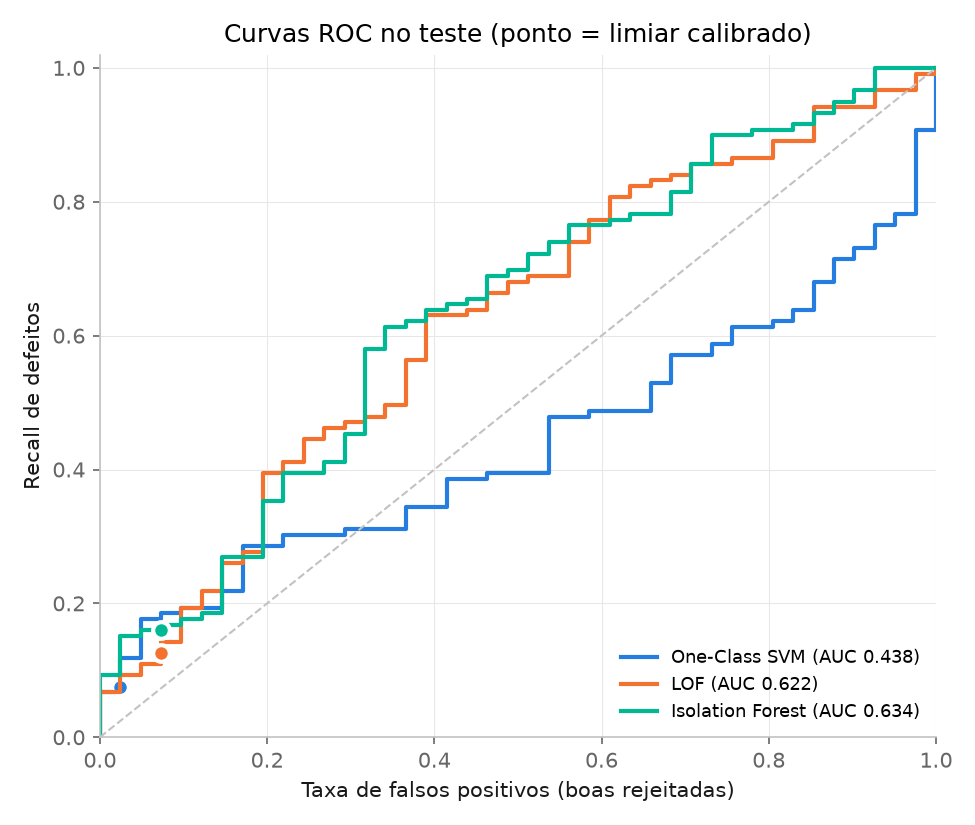

In [3]:
display(Image(R / 'stage8/test_evaluation_classical_v1/figures/roc_curves.png'))

## Etapa 9: divisão do teste
Metade dos defeitos (estratificada) para seleção, outra metade e 21 boas para o holdout.

In [4]:
split = json.loads((R / 'stage9/defect_split_v1.json').read_text())
for nome in ('selection_ids', 'holdout_ids'):
    print(nome, pd.Series([split['classes'][p] for p in split[nome]]).value_counts().to_dict())

selection_ids {'good': 20, 'manipulated_front': 12, 'scratch_head': 12, 'scratch_neck': 12, 'thread_side': 11, 'thread_top': 11}
holdout_ids {'good': 21, 'scratch_neck': 13, 'manipulated_front': 12, 'scratch_head': 12, 'thread_side': 12, 'thread_top': 12}


## Busca na metade de seleção
AUC entre as 64 boas reservadas e os 58 defeitos de seleção.

In [5]:
runs = pd.read_json(R / 'stage9/selection_v1/runs.jsonl', lines=True)
grade = runs[runs.tag == 'grade']
grade.sort_values('auc_sel', ascending=False).groupby('model').head(3)[['model','config','params','auc_sel','recall95_sel']]

,model,config,params,auc_sel,recall95_sel
57,lof,P32-hog+lbp+gabor+edges+shape-z1-n1-top3,"{""n_neighbors"": 10}",0.984375,0.931034
3,lof,P24-hog+lbp+gabor+edges+shape-z1-n1-top3,"{""n_neighbors"": 20}",0.982759,0.965517
5,lof,P24-hog+lbp+gabor+edges+shape-z1-n1-top3,"{""n_neighbors"": 40}",0.982759,0.965517
11,svm,P24-hog+lbp+gabor+edges+shape-z1-n1-top3,"{""nu"": 0.05}",0.975216,0.931034
13,svm,P24-hog+lbp+gabor+edges+shape-z1-n1-top3,"{""nu"": 0.1}",0.971444,0.879310
10,svm,P24-hog+lbp+gabor+edges+shape-z1-n1-max,"{""nu"": 0.05}",0.962823,0.896552
37,isolation_forest,P24-lbp+gabor+edges+shape-z1-n1-top3,"{""max_samples"": 512, ""n_estimators"": 200}",0.948006,0.775862
9,isolation_forest,P24-hog+lbp+gabor+edges+shape-z1-n1-top3,"{""max_samples"": 512, ""n_estimators"": 200}",0.943427,0.775862
35,isolation_forest,P24-lbp+gabor+edges+shape-z1-n1-top3,"{""max_samples"": ""auto"", ""n_estimators"": 200}",0.941002,0.810345


In [6]:
pd.DataFrame(json.loads((R / 'stage9/selection_v1/selection.json').read_text())['selected']).T

,config,params,patch,descriptors,neighbors,aggregation,auc_sel,recall95_sel
svm,P24-hog+lbp+gabor+edges+shape-z1-n1-top3,"{""nu"": 0.05}",24,hog+lbp+gabor+edges+shape,1,top3,0.975216,0.931034
lof,P32-hog+lbp+gabor+edges+shape-z1-n1-top3,"{""n_neighbors"": 10}",32,hog+lbp+gabor+edges+shape,1,top3,0.984375,0.931034
isolation_forest,P24-lbp+gabor+edges+shape-z1-n1-top3,"{""max_samples"": 512, ""n_estimators"": 200}",24,lbp+gabor+edges+shape,1,top3,0.948006,0.775862


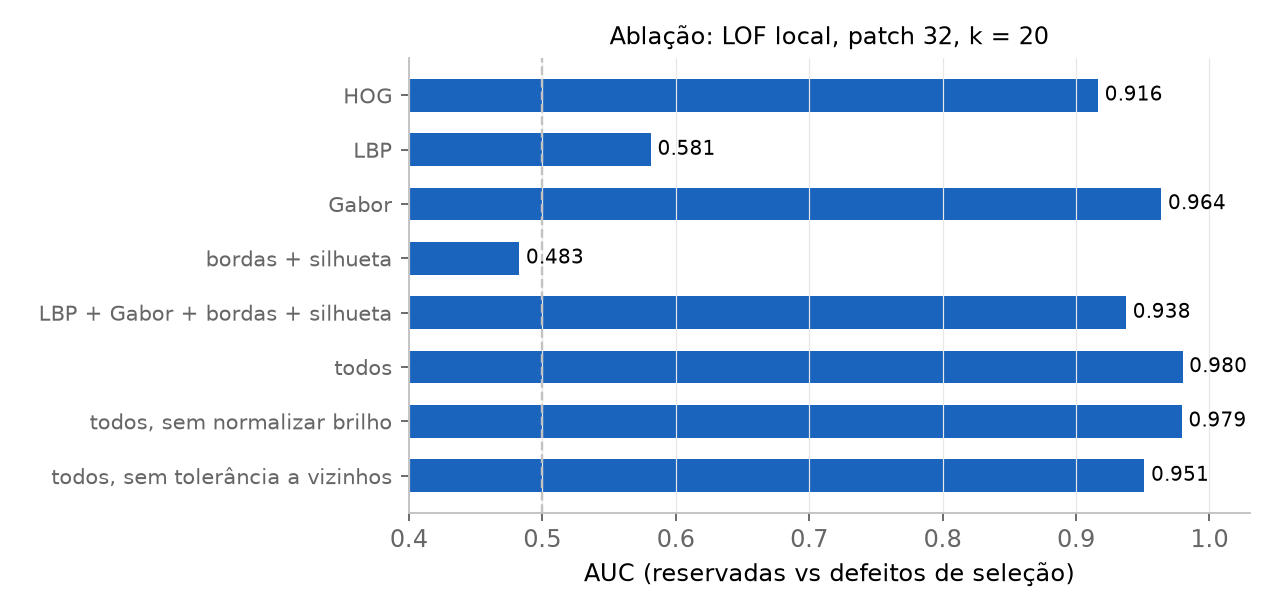

In [7]:
display(Image(R / 'stage9/figures/ablation.png'))

## Resultado no holdout (61 defeitos, 21 boas)

In [8]:
res = json.loads((R / 'stage9/final_v1/holdout_evaluation.json').read_text())['results']
pd.DataFrame(res).T[['fn','fp','tp','tn','recall_defeitos','especificidade','auc_holdout','auc_reservadas_vs_defeitos_holdout']]

,fn,fp,tp,tn,recall_defeitos,especificidade,auc_holdout,auc_reservadas_vs_defeitos_holdout
svm,11,3,50,18,0.819672,0.857143,0.903201,0.934682
lof,2,3,59,18,0.967213,0.857143,0.957845,0.985656
isolation_forest,19,2,42,19,0.688525,0.904762,0.910226,0.923668


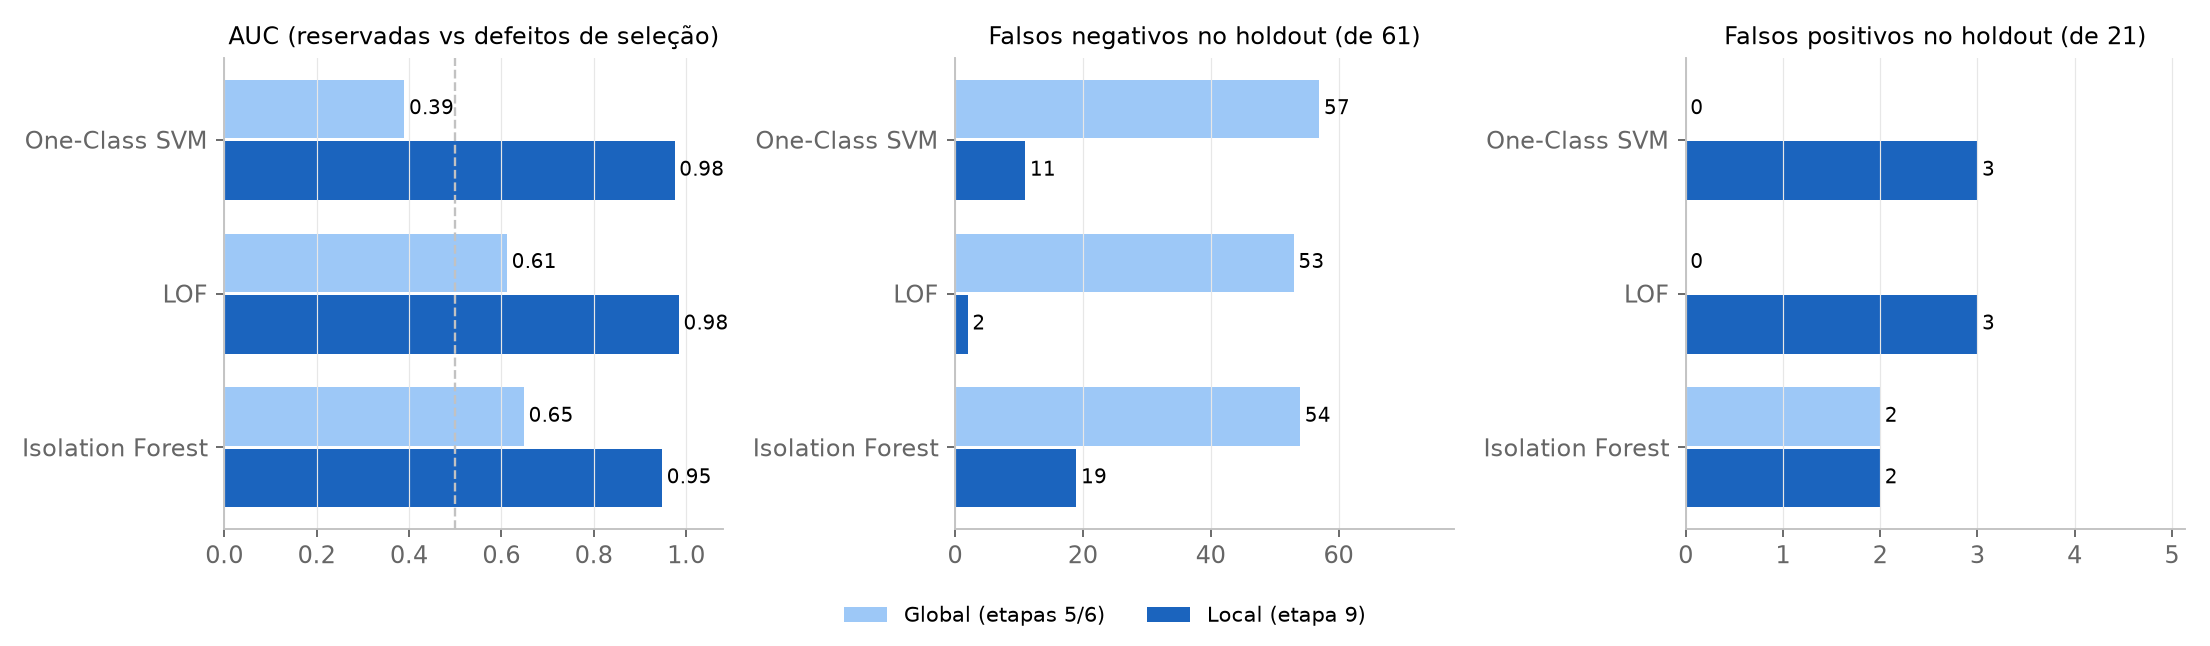

In [9]:
display(Image(R / 'stage9/figures/before_after.png'))

## Onde está o defeito (LOF local)

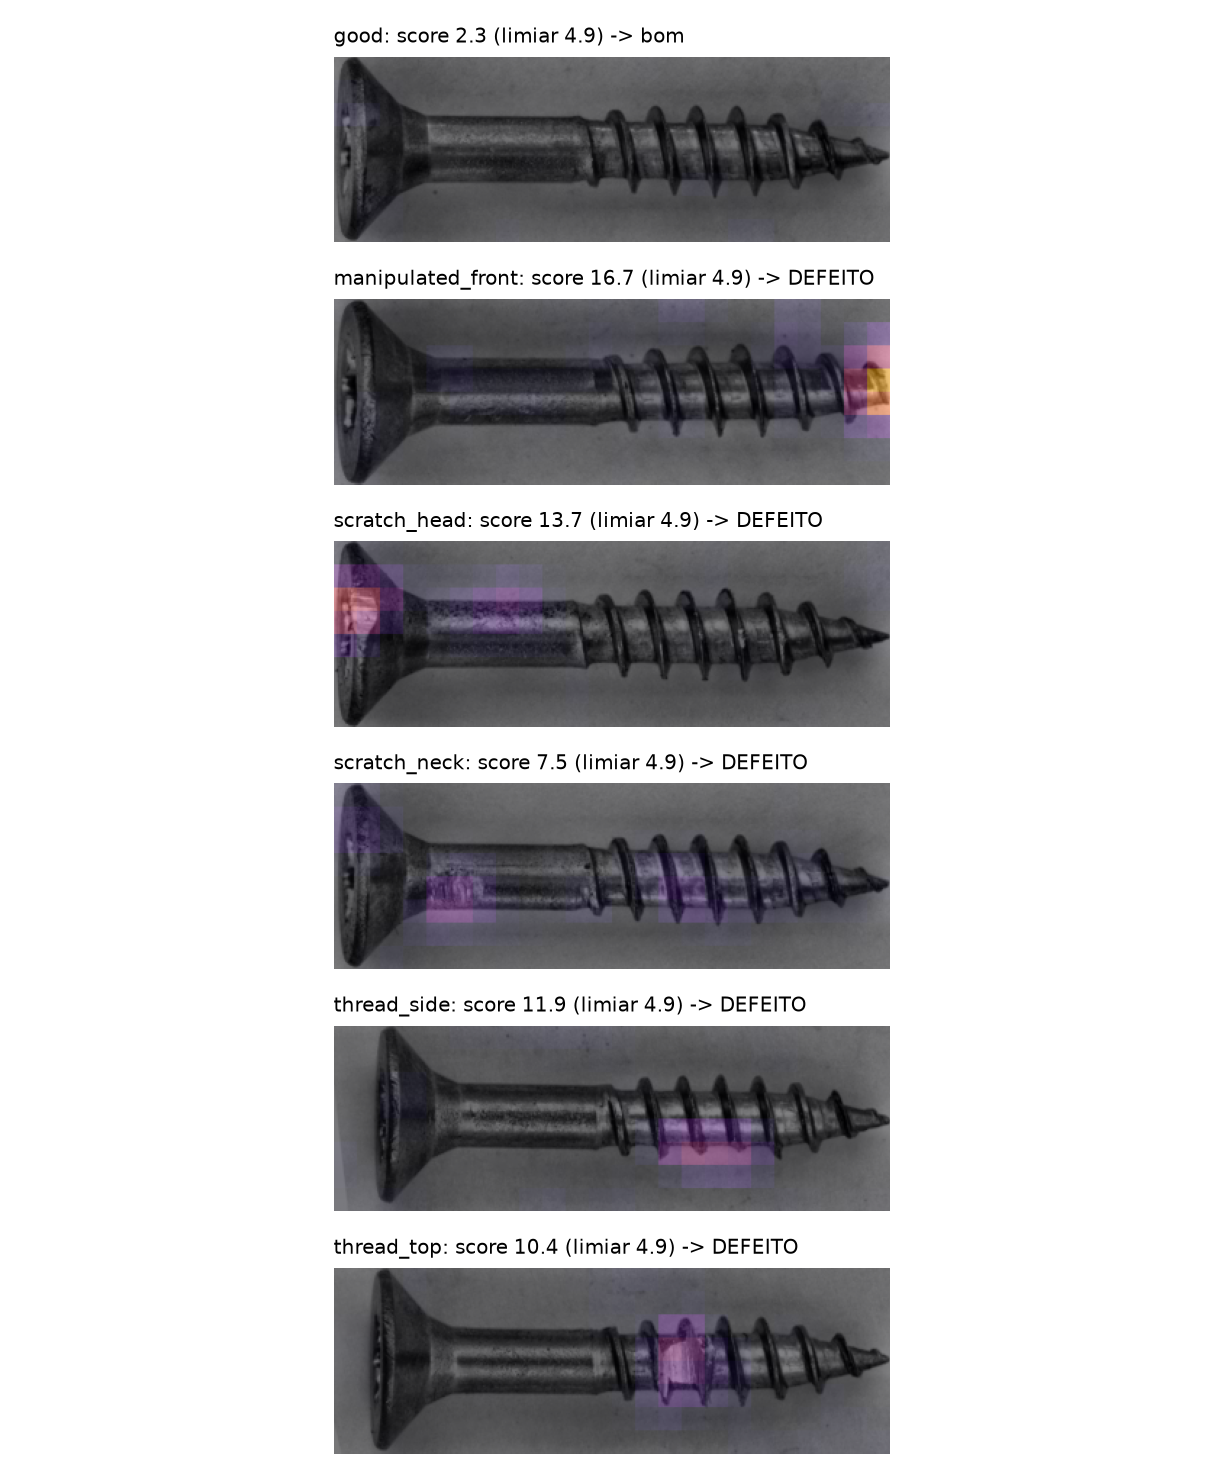

In [10]:
display(Image(R / 'stage9/figures/local_maps_lof.png'))